# Continuum subtraction for an Upper Sco spectrum

This example uses the raw Upper Sco source J16120505. The CSV is included in `Realobs_data/Raw_data/`, so the notebook does not need the original FITS file or local model grids. Its `wave`, `flux`, and `err` columns are wavelength in µm, flux density in Jy, and measurement error in Jy. Run this notebook from the repository root or `notebooks/` directory.

In [10]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from diskmelts import consub

# Change this filename to try another CSV in Realobs_data/Raw_data/.
ROOT = Path.cwd()
if not (ROOT / "Realobs_data" / "Raw_data").is_dir():
    ROOT = ROOT.parent
RAW_CSV = ROOT / "Realobs_data" / "Raw_data" / "j16120505_1d_v9.0.csv"
if not RAW_CSV.is_file():
    raise FileNotFoundError(f"USco CSV not found: {RAW_CSV}")

wav, flux, error = consub.read_spectrum(RAW_CSV)

keep = (wav >= 4.9) & (wav <= 25.0)
wav, flux, error = wav[keep], flux[keep], error[keep]
print(f"Loaded {RAW_CSV.name}: {len(wav)} pixels from {wav[0]:.2f} to {wav[-1]:.2f} µm")

Loaded j16120505_1d_v9.0.csv: 10239 pixels from 4.90 to 25.00 µm


## Calculate the continuum and diagnostic masks

This Upper Sco example uses the `ttauri` preset and robust method. `exclude=None` below adds no wavelength exclusion; set `exclude=[[12.0, 13.0]]` if you want to omit 12–13 µm. `subtract_continuum()` also returns masks for calibration pixels, excluded pixels, and weakly supported continuum regions. The `err` array describes measurement or local noise, not uncertainty in continuum placement.


In [ ]:
diagnostics = consub.subtract_continuum(
    wav, flux, error=error, preset="ttauri",
    exclude=None, method="robust",
)
wav = diagnostics.wave.to_numpy(copy=True)
corrected = diagnostics.flux.to_numpy(copy=True)
noise = diagnostics.err.to_numpy(copy=True)
continuum = diagnostics.cont.to_numpy(copy=True)
cont_orig = diagnostics.cont_unshifted.to_numpy(copy=True)
print(f"Residual plus continuum reproduces the input: "
      f"{np.allclose(corrected + continuum, flux, equal_nan=True)}")

Residual plus continuum reproduces the input: True


/var/folders/4w/sbdbrvfs7lx3bz_3rmhyvhsr0000gp/T/ipykernel_12553/3273183778.py:1: UserWarning: Continuum crosses regions with weak support; inspect the plot or subtract_continuum() diagnostics before using those regions
  diagnostics = consub.subtract_continuum(


## Inspect the result

The upper panels show the raw spectrum and continuum; the lower panels show the continuum-subtracted residual. The shaded regions and points mean:

- **Green points — calibration pixels:** `reference_mask` pixels used to calibrate the continuum correction.
- **Light red shading — excluded wavelengths:** `excluded` pixels omitted from the fit by an `exclude` setting. With `exclude=None` below, there is no red shading.
- **Orange shading — weak continuum support:** `weak_support` pixels too far from nearby calibration points, or outside their wavelength coverage. The continuum there depends more on interpolation or extrapolation; its placement is less reliable, and `cont_err` is `NaN`. Orange and red can overlap.

Inspect orange regions and any excluded interval before using the residual for scientific measurements.


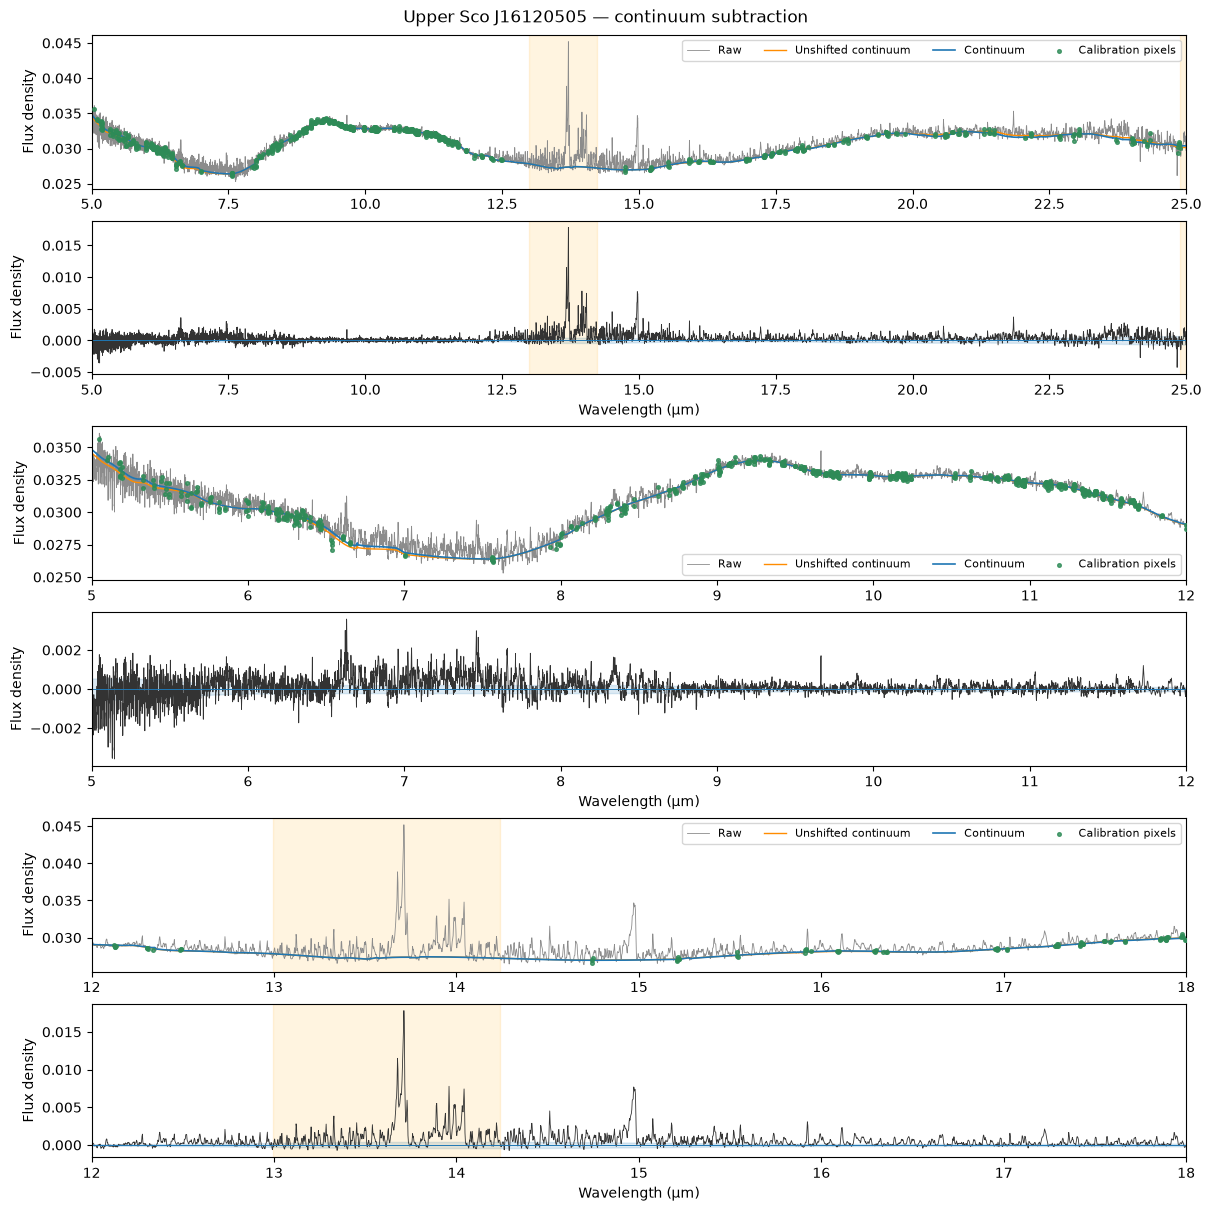

In [14]:
fig = consub.plot_consub(
    diagnostics,
    ranges=[(5,25),(5.0, 12.0), (12.0, 18.0)],
    title="Upper Sco J16120505 — continuum subtraction",
)
plt.show()


To save the figure, pass `output="figures/consub/J16120505.png"` to `consub.plot_consub()`. To process another Upper Sco source, change `RAW_CSV` to one of the CSVs in `Realobs_data/Raw_data/`. For more settings and diagnostic outputs, see the [continuum guide](https://diskmelts.readthedocs.io/en/latest/continuum.html).